#robustez deadband vc top 5

In [57]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


base = pd.read_excel(
    r"C:\Users\julio\PBL FGV\FGV QUANT\treinee\TraineeFGVquant\bases de dados\economatica-3.xlsx",
    header=3
)

display(base.head())

,Data,Fechamento\najust p/ prov\nEm moeda orig\nABEV3,Fechamento\najust p/ prov\nEm moeda orig\nB3SA3,Fechamento\najust p/ prov\nEm moeda orig\nBBDC4,Fechamento\najust p/ prov\nEm moeda orig\nBBAS3,Fechamento\najust p/ prov\nEm moeda orig\nBRKM5,Fechamento\najust p/ prov\nEm moeda orig\nCAML3,Fechamento\najust p/ prov\nEm moeda orig\nCMIG4,Fechamento\najust p/ prov\nEm moeda orig\nCYRE3,Fechamento\najust p/ prov\nEm moeda orig\nEMBJ3,...,Fechamento\najust p/ prov\nEm moeda orig\nPETR4,Fechamento\najust p/ prov\nEm moeda orig\nPRIO3,Fechamento\najust p/ prov\nEm moeda orig\nRADL3,Fechamento\najust p/ prov\nEm moeda orig\nSANB3,Fechamento\najust p/ prov\nEm moeda orig\nSANB11,Fechamento\najust p/ prov\nEm moeda orig\nCSNA3,Fechamento\najust p/ prov\nEm moeda orig\nTAEE11,Fechamento\najust p/ prov\nEm moeda orig\nUSIM5,Fechamento\najust p/ prov\nEm moeda orig\nVALE3,Fechamento\najust p/ prov\nEm moeda orig\nWEGE3
0,2015-01-01,-,-,-,-,-,-,-,-,-,...,-,-,-,-,-,-,-,-,-,-
1,2015-01-02,10.017999,1.992412,6.786634,5.277083,11.473244,-,2.302507,5.016306,23.600926,...,2.211391,0.439294,4.094378,3.046185,5.848384,2.781842,5.698713,3.669706,9.711643,4.738303
2,2015-01-05,9.798992,1.933689,6.800631,5.16758,10.78129,-,2.243146,5.145914,23.078572,...,2.034196,0.406347,4.048521,3.079871,5.839188,2.676971,5.73538,3.447532,9.565603,4.710844
3,2015-01-06,10.080572,1.952564,7.024349,5.239805,10.550639,-,2.223359,5.289923,22.660688,...,1.968043,0.366411,4.117306,3.060622,5.839188,2.859115,5.790381,3.616078,9.948958,4.639144
4,2015-01-07,10.330865,2.036455,7.303501,5.470459,10.544049,-,2.239548,5.429131,22.489736,...,2.048372,0.365413,4.225398,3.368609,6.165631,3.168209,5.75677,3.830591,10.314057,4.631516


In [58]:
precos = base.copy()

precos.columns = ["Data"] + [
    str(col).strip().split("\n")[-1]
    for col in precos.columns[1:]
]

precos["Data"] = pd.to_datetime(precos["Data"], errors="coerce")
precos = precos.dropna(subset=["Data"])
precos = precos.set_index("Data").sort_index()

precos = precos.replace("-", np.nan)
precos = precos.apply(pd.to_numeric, errors="coerce")

# Remover dias em que TODAS as ações estão sem cotação
precos = precos.dropna(how="all")
precos = precos.ffill(limit=1)
precos = precos.loc[:"2021-12-31"]

display(precos.head())

C:\Users\julio\AppData\Local\Temp\ipykernel_4668\1577949936.py:12: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  precos = precos.replace("-", np.nan)


,ABEV3,B3SA3,BBDC4,BBAS3,BRKM5,CAML3,CMIG4,CYRE3,EMBJ3,EGIE3,...,PETR4,PRIO3,RADL3,SANB3,SANB11,CSNA3,TAEE11,USIM5,VALE3,WEGE3
Data,,,,,,,,,,,,,,,,,,,,,
2015-01-02,10.017999,1.992412,6.786634,5.277083,11.473244,NaN,2.302507,5.016306,23.600926,9.445198,...,2.211391,0.439294,4.094378,3.046185,5.848384,2.781842,5.698713,3.669706,9.711643,4.738303
2015-01-05,9.798992,1.933689,6.800631,5.167580,10.781290,NaN,2.243146,5.145914,23.078572,9.456784,...,2.034196,0.406347,4.048521,3.079871,5.839188,2.676971,5.735380,3.447532,9.565603,4.710844
2015-01-06,10.080572,1.952564,7.024349,5.239805,10.550639,NaN,2.223359,5.289923,22.660688,9.647947,...,1.968043,0.366411,4.117306,3.060622,5.839188,2.859115,5.790381,3.616078,9.948958,4.639144
2015-01-07,10.330865,2.036455,7.303501,5.470459,10.544049,NaN,2.239548,5.429131,22.489736,9.891245,...,2.048372,0.365413,4.225398,3.368609,6.165631,3.168209,5.756770,3.830591,10.314057,4.631516
2015-01-08,10.372405,2.015482,7.341118,5.489098,10.570409,NaN,2.205370,5.472334,21.843916,9.992620,...,2.168864,0.377394,4.258153,3.310861,6.069078,3.090936,5.811771,3.639062,10.423587,4.691012


In [59]:
retornos = precos.pct_change(fill_method=None)
display(retornos.head())

,ABEV3,B3SA3,BBDC4,BBAS3,BRKM5,CAML3,CMIG4,CYRE3,EMBJ3,EGIE3,...,PETR4,PRIO3,RADL3,SANB3,SANB11,CSNA3,TAEE11,USIM5,VALE3,WEGE3
Data,,,,,,,,,,,,,,,,,,,,,
2015-01-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2015-01-05,-0.021861,-0.029474,0.002062,-0.020751,-0.060310,NaN,-0.025781,0.025837,-0.022133,0.001227,...,-0.080128,-0.075000,-0.011200,0.011058,-0.001572,-0.037698,0.006434,-0.060543,-0.015038,-0.005795
2015-01-06,0.028736,0.009761,0.032897,0.013977,-0.021394,NaN,-0.008821,0.027985,-0.018107,0.020214,...,-0.032520,-0.098280,0.016990,-0.006250,0.000000,0.068041,0.009590,0.048889,0.040076,-0.015220
2015-01-07,0.024829,0.042965,0.039741,0.044020,-0.000625,NaN,0.007282,0.026316,-0.007544,0.025218,...,0.040816,-0.002725,0.026253,0.100629,0.055906,0.108108,-0.005805,0.059322,0.036697,-0.001644
2015-01-08,0.004021,-0.010299,0.005150,0.003407,0.002500,NaN,-0.015261,0.007958,-0.028716,0.010249,...,0.058824,0.032787,0.007752,-0.017143,-0.015660,-0.024390,0.009554,-0.050000,0.010619,0.012846


In [60]:
momentum = precos.shift(21) / precos.shift(252) -1
display(momentum.tail())

ranking = momentum.iloc[-1].dropna().sort_values(ascending=False)
display(ranking.head(30))

,ABEV3,B3SA3,BBDC4,BBAS3,BRKM5,CAML3,CMIG4,CYRE3,EMBJ3,EGIE3,...,PETR4,PRIO3,RADL3,SANB3,SANB11,CSNA3,TAEE11,USIM5,VALE3,WEGE3
Data,,,,,,,,,,,,,,,,,,,,,
2021-12-23,0.133406,-0.342244,-0.081341,-0.168918,1.407355,-0.158859,0.189861,-0.497636,1.222222,-0.057207,...,0.115631,0.971552,-0.061573,-0.124225,-0.124237,-0.151832,0.140679,0.057822,-0.011946,-0.068008
2021-12-27,0.123253,-0.350941,-0.094488,-0.133768,1.312054,-0.179926,0.204867,-0.467392,1.281996,-0.076701,...,0.150738,0.966162,-0.069179,-0.133003,-0.125140,-0.139683,0.152570,0.069429,-0.038205,-0.067553
2021-12-28,0.071790,-0.380876,-0.134834,-0.163211,1.089627,-0.161181,0.153674,-0.479329,1.115258,-0.072849,...,0.104102,0.729614,-0.119033,-0.147190,-0.134566,-0.211107,0.150081,0.007026,-0.074104,-0.127573
2021-12-29,0.035175,-0.392072,-0.142767,-0.155635,1.198821,-0.169294,0.146392,-0.492190,1.206704,-0.077000,...,0.148577,0.836123,-0.108238,-0.163988,-0.141829,-0.227629,0.182637,0.018150,-0.068910,-0.100623
2021-12-30,0.046468,-0.401739,-0.137068,-0.097158,1.150838,-0.139394,0.158131,-0.505191,1.241218,-0.073983,...,0.192865,0.792403,-0.094976,-0.169463,-0.152890,-0.265472,0.183218,0.020614,-0.052740,-0.095395


EMBJ3     1.241218
BRKM5     1.150838
PRIO3     0.792403
GGBR4     0.197384
PETR4     0.192865
KLBN3     0.188478
TAEE11    0.183218
GOAU4     0.178467
CMIG4     0.158131
EQTL3     0.047175
ABEV3     0.046468
USIM5     0.020614
KLBN11   -0.025824
VALE3    -0.052740
EGIE3    -0.073983
RADL3    -0.094976
WEGE3    -0.095395
ITUB4    -0.096929
BBAS3    -0.097158
BBDC4    -0.137068
CAML3    -0.139394
SANB11   -0.152890
MULT3    -0.160731
SANB3    -0.169463
RENT3    -0.218382
CSNA3    -0.265472
B3SA3    -0.401739
MRVE3    -0.404784
CYRE3    -0.505191
MGLU3    -0.687449
Name: 2021-12-30 00:00:00, dtype: float64

In [61]:
momentum_mensal= momentum.groupby(momentum.index.to_period("M")).tail(1)
momentum_mensal = momentum_mensal.loc["2017":"2021"]
display(momentum_mensal.head())

,ABEV3,B3SA3,BBDC4,BBAS3,BRKM5,CAML3,CMIG4,CYRE3,EMBJ3,EGIE3,...,PETR4,PRIO3,RADL3,SANB3,SANB11,CSNA3,TAEE11,USIM5,VALE3,WEGE3
Data,,,,,,,,,,,,,,,,,,,,,
2017-01-31,-0.049871,0.641078,0.922764,1.264395,0.633686,NaN,0.585056,0.495430,-0.402685,0.149892,...,2.232609,2.111429,0.556932,1.890813,1.331449,2.144928,0.412806,3.848779,1.768583,0.079252
2017-02-24,0.010063,0.700404,0.836687,1.552062,0.492969,NaN,0.659540,0.614453,-0.387798,0.086484,...,2.231084,1.966667,0.510534,1.758837,1.355547,1.323755,0.359660,4.571725,2.066916,0.243964
2017-03-31,-0.071286,0.230041,0.356670,0.700372,0.517953,NaN,0.397465,0.241869,-0.255655,0.031530,...,0.790284,0.870886,0.152750,1.225020,1.022576,0.575839,0.297034,1.715847,1.036347,0.235702
2017-04-28,-0.036421,0.150305,0.304109,0.580393,0.339691,NaN,0.605699,0.284426,-0.178468,-0.015971,...,0.442606,1.224658,0.133202,0.822507,0.712024,-0.208943,0.222214,0.808333,0.604342,0.215807
2017-05-31,-0.005684,0.238164,0.493541,1.164736,0.727379,NaN,0.810329,0.407546,-0.216047,0.012516,...,0.699878,1.803960,0.252594,0.789552,0.672961,0.233281,0.340706,1.594118,1.041041,0.274934


In [62]:
def criar_top_n(momentum_mensal, n):

    historico = {}

    for data, linha in momentum_mensal.iterrows():

        ranking = linha.dropna()

        if len(ranking) < n:
            continue

        melhores = ranking.nlargest(n).index.tolist()

        historico[data] = melhores

    colunas = [f"Ativo {i}" for i in range(1, n + 1)]

    return pd.DataFrame.from_dict(
        historico,
        orient="index",
        columns=colunas
    )

In [63]:
top10 = criar_top_n(momentum_mensal, 10)

top15 = criar_top_n(momentum_mensal, 15)

display(top10.head())
display(top15.head())

,Ativo 1,Ativo 2,Ativo 3,Ativo 4,Ativo 5,Ativo 6,Ativo 7,Ativo 8,Ativo 9,Ativo 10
2017-01-31,MGLU3,GOAU4,USIM5,PETR4,GGBR4,CSNA3,PRIO3,SANB3,VALE3,SANB11
2017-02-24,MGLU3,USIM5,GOAU4,GGBR4,PETR4,VALE3,PRIO3,SANB3,BBAS3,SANB11
2017-03-31,MGLU3,USIM5,GOAU4,SANB3,VALE3,SANB11,GGBR4,PRIO3,PETR4,BBAS3
2017-04-28,MGLU3,PRIO3,GOAU4,SANB3,USIM5,SANB11,CMIG4,VALE3,BBAS3,PETR4
2017-05-31,MGLU3,PRIO3,USIM5,GOAU4,BBAS3,VALE3,CMIG4,SANB3,GGBR4,BRKM5


,Ativo 1,Ativo 2,Ativo 3,Ativo 4,Ativo 5,Ativo 6,Ativo 7,Ativo 8,Ativo 9,Ativo 10,Ativo 11,Ativo 12,Ativo 13,Ativo 14,Ativo 15
2017-01-31,MGLU3,GOAU4,USIM5,PETR4,GGBR4,CSNA3,PRIO3,SANB3,VALE3,SANB11,BBAS3,BBDC4,RENT3,ITUB4,B3SA3
2017-02-24,MGLU3,USIM5,GOAU4,GGBR4,PETR4,VALE3,PRIO3,SANB3,BBAS3,SANB11,CSNA3,BBDC4,ITUB4,B3SA3,RENT3
2017-03-31,MGLU3,USIM5,GOAU4,SANB3,VALE3,SANB11,GGBR4,PRIO3,PETR4,BBAS3,CSNA3,BRKM5,EQTL3,ITUB4,CMIG4
2017-04-28,MGLU3,PRIO3,GOAU4,SANB3,USIM5,SANB11,CMIG4,VALE3,BBAS3,PETR4,GGBR4,EQTL3,ITUB4,BRKM5,BBDC4
2017-05-31,MGLU3,PRIO3,USIM5,GOAU4,BBAS3,VALE3,CMIG4,SANB3,GGBR4,BRKM5,PETR4,SANB11,MRVE3,ITUB4,BBDC4


In [64]:
top5 = {}
for data, linha in momentum_mensal.iterrows():


 ranking = linha.dropna()

 if len(ranking) < 5:
  continue
 melhores = ranking.nlargest(5).index.tolist()
 top5[data] = melhores
top5 = pd.DataFrame.from_dict(top5, orient="index", columns=["Ativo 1", "Ativo 2", "Ativo 3", "Ativo 4", "Ativo 5"])
display(top5.head())

,Ativo 1,Ativo 2,Ativo 3,Ativo 4,Ativo 5
2017-01-31,MGLU3,GOAU4,USIM5,PETR4,GGBR4
2017-02-24,MGLU3,USIM5,GOAU4,GGBR4,PETR4
2017-03-31,MGLU3,USIM5,GOAU4,SANB3,VALE3
2017-04-28,MGLU3,PRIO3,GOAU4,SANB3,USIM5
2017-05-31,MGLU3,PRIO3,USIM5,GOAU4,BBAS3


In [65]:
pesos_top5 = pd.DataFrame(
    0.0,
    index=top5.index,
    columns=retornos.columns
)

for data, linha in top5.iterrows():

    ativos = linha.tolist()

    pesos_top5.loc[data, ativos] = 0.20

display(pesos_top5.head())


,ABEV3,B3SA3,BBDC4,BBAS3,BRKM5,CAML3,CMIG4,CYRE3,EMBJ3,EGIE3,...,PETR4,PRIO3,RADL3,SANB3,SANB11,CSNA3,TAEE11,USIM5,VALE3,WEGE3
2017-01-31,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.2,0.0,0.0,0.0,0.0,0.0,0.0,0.2,0.0,0.0
2017-02-24,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.2,0.0,0.0,0.0,0.0,0.0,0.0,0.2,0.0,0.0
2017-03-31,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.2,0.0,0.0,0.0,0.2,0.2,0.0
2017-04-28,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.2,0.0,0.2,0.0,0.0,0.0,0.2,0.0,0.0
2017-05-31,0.0,0.0,0.0,0.2,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.2,0.0,0.0,0.0,0.0,0.0,0.2,0.0,0.0


In [66]:
ordens = pesos_top5.reindex(retornos.index).shift(1)
# Começamos sem posições
pesos_atuais = pd.Series(0.0, index=retornos.columns)

# Armazenar os retornos da carteira
retorno_top5 = pd.Series(index=retornos.index, dtype=float)

for data in retornos.index:

    r = retornos.loc[data]

    # Verificar se faltam retornos de ações compradas
    if r[pesos_atuais > 0].isna().any():
        raise ValueError(f"Retorno ausente em {data}")

    r = r.fillna(0)

    # Calcular o retorno diário da carteira
    retorno_dia = (pesos_atuais * r).sum()

    retorno_top5.loc[data] = retorno_dia

    # Atualizar os pesos após os retornos do dia
    pesos_atuais = pesos_atuais * (1 + r) / (1 + retorno_dia)

    # Executar novas ordens no fechamento, quando houver
    if ordens.loc[data].notna().all():
        pesos_atuais = ordens.loc[data].copy()

# Manter apenas o período de análise
retorno_top5 = retorno_top5.loc["2017":"2021"]

display(retorno_top5.tail())

Data
2021-12-23    0.005857
2021-12-27    0.013029
2021-12-28   -0.009635
2021-12-29    0.000153
2021-12-30    0.017159
dtype: float64

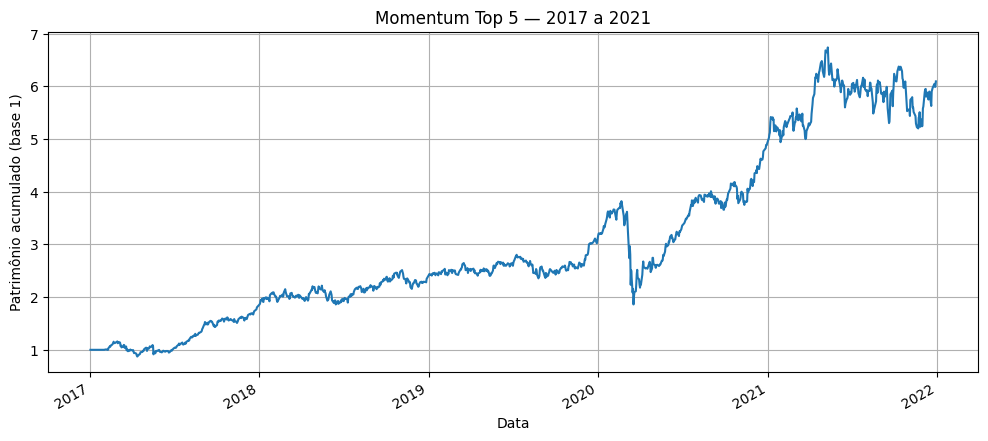

In [67]:
patrimonio_top5 = (1 + retorno_top5).cumprod()

patrimonio_top5.plot(figsize=(12, 5))

plt.title("Momentum Top 5 — 2017 a 2021")
plt.ylabel("Patrimônio acumulado (base 1)")
plt.xlabel("Data")
plt.grid(True)
plt.show()

In [68]:
def criar_deadband(momentum_mensal, limite):
 carteira = []
 historico = {}
 for data, linha in momentum_mensal.iterrows():
  ranking = linha.dropna().sort_values(ascending=False)
  if len(ranking) < 5:
   continue
  permitidos = ranking.head(limite).index
  carteira = [ativo for ativo in carteira if ativo in permitidos]
  for ativo in ranking.index:
   if len(carteira) == 5:
    break
   if ativo not in carteira:
    carteira.append(ativo)
    historico[data] = carteira.copy()
 return pd.DataFrame.from_dict(
        historico,
        orient="index",
        columns=["Ativo 1", "Ativo 2", "Ativo 3", "Ativo 4", "Ativo 5"])

In [69]:
deadband7 = criar_deadband(momentum_mensal, limite=7)

deadband10 = criar_deadband(momentum_mensal, limite=10)

display(deadband7.head())
display(deadband10.head())

,Ativo 1,Ativo 2,Ativo 3,Ativo 4,Ativo 5
2017-01-31,MGLU3,GOAU4,USIM5,PETR4,GGBR4
2017-03-31,MGLU3,GOAU4,USIM5,GGBR4,SANB3
2017-04-28,MGLU3,GOAU4,USIM5,SANB3,PRIO3
2017-05-31,MGLU3,GOAU4,USIM5,PRIO3,BBAS3
2017-07-31,MGLU3,GOAU4,USIM5,PRIO3,BRKM5


,Ativo 1,Ativo 2,Ativo 3,Ativo 4,Ativo 5
2017-01-31,MGLU3,GOAU4,USIM5,PETR4,GGBR4
2017-04-28,MGLU3,GOAU4,USIM5,PETR4,PRIO3
2017-05-31,MGLU3,GOAU4,USIM5,PRIO3,BBAS3
2017-10-31,MGLU3,USIM5,PRIO3,BBAS3,BRKM5
2017-12-28,MGLU3,USIM5,PRIO3,RENT3,B3SA3


In [70]:
def criar_pesos(carteira):
    pesos = pd.DataFrame( 0.0,
        index=carteira.index,
        columns=retornos.columns)
    for data, linha in carteira.iterrows():

        ativos = linha.dropna().tolist()

        pesos.loc[data, ativos] = 1 / len(ativos)

    return pesos


In [71]:
pesos_top10 = criar_pesos(top10)

pesos_top15 = criar_pesos(top15)

In [72]:
pesos_deadband7 = criar_pesos(deadband7)

pesos_deadband10 = criar_pesos(deadband10)

display(pesos_deadband7.head())
display(pesos_deadband10.head())

,ABEV3,B3SA3,BBDC4,BBAS3,BRKM5,CAML3,CMIG4,CYRE3,EMBJ3,EGIE3,...,PETR4,PRIO3,RADL3,SANB3,SANB11,CSNA3,TAEE11,USIM5,VALE3,WEGE3
2017-01-31,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.2,0.0,0.0,0.0,0.0,0.0,0.0,0.2,0.0,0.0
2017-03-31,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.2,0.0,0.0,0.0,0.2,0.0,0.0
2017-04-28,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.2,0.0,0.2,0.0,0.0,0.0,0.2,0.0,0.0
2017-05-31,0.0,0.0,0.0,0.2,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.2,0.0,0.0,0.0,0.0,0.0,0.2,0.0,0.0
2017-07-31,0.0,0.0,0.0,0.0,0.2,0.0,0.0,0.0,0.0,0.0,...,0.0,0.2,0.0,0.0,0.0,0.0,0.0,0.2,0.0,0.0


,ABEV3,B3SA3,BBDC4,BBAS3,BRKM5,CAML3,CMIG4,CYRE3,EMBJ3,EGIE3,...,PETR4,PRIO3,RADL3,SANB3,SANB11,CSNA3,TAEE11,USIM5,VALE3,WEGE3
2017-01-31,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.2,0.0,0.0,0.0,0.0,0.0,0.0,0.2,0.0,0.0
2017-04-28,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.2,0.2,0.0,0.0,0.0,0.0,0.0,0.2,0.0,0.0
2017-05-31,0.0,0.0,0.0,0.2,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.2,0.0,0.0,0.0,0.0,0.0,0.2,0.0,0.0
2017-10-31,0.0,0.0,0.0,0.2,0.2,0.0,0.0,0.0,0.0,0.0,...,0.0,0.2,0.0,0.0,0.0,0.0,0.0,0.2,0.0,0.0
2017-12-28,0.0,0.2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.2,0.0,0.0,0.0,0.0,0.0,0.2,0.0,0.0


In [73]:
def backtest(pesos_alvo, retornos):

    ordens = pesos_alvo.reindex(retornos.index).shift(1)
    pesos_atuais = pd.Series(0.0, index=retornos.columns)
    historico = []

    for data, r in retornos.iterrows():

        # Verificar retornos ausentes dos ativos comprados
        ativos_faltantes = r[pesos_atuais > 0]
        ativos_faltantes = ativos_faltantes[ativos_faltantes.isna()]

        if not ativos_faltantes.empty:
            print("Data:", data)
            print("Ativos sem retorno:", ativos_faltantes.index.tolist())
            raise ValueError("Retorno ausente")

        r = r.fillna(0)

        # Retorno diário da carteira
        retorno_dia = (pesos_atuais * r).sum()

        # Atualizar pesos após variação dos preços
        pesos_atuais = pesos_atuais * (1 + r) / (1 + retorno_dia)

        # Verificar se há rebalanceamento
        turnover = 0

        if ordens.loc[data].notna().all():

            novos_pesos = ordens.loc[data]

            turnover = (novos_pesos - pesos_atuais).abs().sum()

            pesos_atuais = novos_pesos.copy()

        historico.append({
            "Data": data,
            "Retorno": retorno_dia,
            "Turnover": turnover
        })

    resultado = pd.DataFrame(historico).set_index("Data")

    return resultado.loc["2017":"2021"]

In [74]:
resultado_top10 = backtest(pesos_top10, retornos)

resultado_top15 = backtest(pesos_top15, retornos)
print("Top 10:")
print(resultado_top10.index.min())
print(resultado_top10.index.max())

print("\nTop 15:")
print(resultado_top15.index.min())
print(resultado_top15.index.max())

Top 10:
2017-01-02 00:00:00
2021-12-30 00:00:00

Top 15:
2017-01-02 00:00:00
2021-12-30 00:00:00


In [75]:
resultado_top5 = backtest(pesos_top5, retornos)

resultado_db7 = backtest(pesos_deadband7, retornos)

resultado_db10 = backtest(pesos_deadband10, retornos)

comparacao = pd.DataFrame({
    "Top 5": resultado_top5["Retorno"],
    "Deadband 7": resultado_db7["Retorno"],
    "Deadband 10": resultado_db10["Retorno"]
})

display(comparacao.tail())

,Top 5,Deadband 7,Deadband 10
Data,,,
2021-12-23,0.005857,0.005857,0.006704
2021-12-27,0.013029,0.013029,0.013689
2021-12-28,-0.009635,-0.009635,-0.008404
2021-12-29,0.000153,0.000153,0.000695
2021-12-30,0.017159,0.017159,0.014419


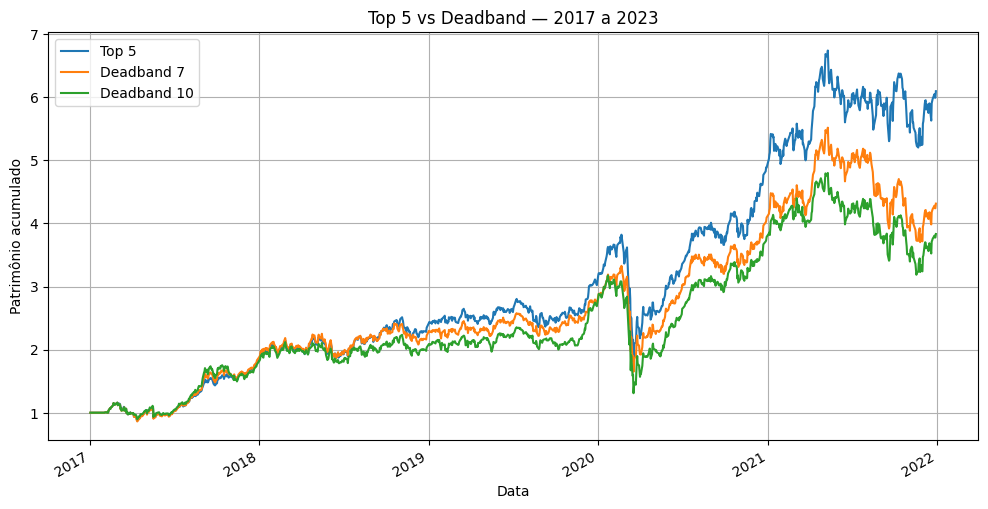

In [76]:
patrimonio = (1 + comparacao).cumprod()

patrimonio.plot(figsize=(12, 6))

plt.title("Top 5 vs Deadband — 2017 a 2023")
plt.ylabel("Patrimônio acumulado")
plt.xlabel("Data")
plt.grid(True)
plt.show()

In [77]:
def calcular_sharpe(retornos):
    media = retornos.mean()
    volatilidade = retornos.std()

    sharpe = (media / volatilidade) * np.sqrt(252)

    return sharpe

In [78]:
sharpe_top5 = calcular_sharpe(resultado_top5["Retorno"])
sharpe_db7 = calcular_sharpe(resultado_db7["Retorno"])
sharpe_db10 = calcular_sharpe(resultado_db10["Retorno"])

comparacao_sharpe = pd.DataFrame({
    "Estratégia": ["Top 5", "Deadband 7", "Deadband 10"],
    "Sharpe": [sharpe_top5, sharpe_db7, sharpe_db10]
})

display(comparacao_sharpe.round(3))

,Estratégia,Sharpe
0,Top 5,1.213
1,Deadband 7,1.021
2,Deadband 10,0.913


In [79]:
def calcular_metricas(resultado):

    r = resultado["Retorno"]

    patrimonio = (1 + r).cumprod()

    retorno_anual = patrimonio.iloc[-1] ** (252 / len(r)) - 1

    drawdown = patrimonio / patrimonio.cummax() - 1

    max_drawdown = drawdown.min()

    turnover_anual = resultado["Turnover"].sum() * 252 / len(r)

    return {
        "Retorno anual": retorno_anual,
        "Max Drawdown": max_drawdown,
        "Turnover anual": turnover_anual
    }


In [80]:
metricas = pd.DataFrame({
    "Top 5": calcular_metricas(resultado_top5),
    "Deadband 7": calcular_metricas(resultado_db7),
    "Deadband 10": calcular_metricas(resultado_db10)
}).T

display(metricas.round(3))

,Retorno anual,Max Drawdown,Turnover anual
Top 5,0.446,-0.513,5.976
Deadband 7,0.348,-0.505,4.111
Deadband 10,0.315,-0.588,3.052


In [81]:
def aplicar_custos(resultado, custo):

    retornos_brutos = resultado["Retorno"]

    turnover = resultado["Turnover"]

    retornos_liquidos = (
        (1 + retornos_brutos) * (1 - custo * turnover) - 1
    )

    return retornos_liquidos



In [82]:
estrategias = {
    "Top 5": resultado_top5,
    "Deadband 7": resultado_db7,
    "Deadband 10": resultado_db10
}

custos = [0, 0.001, 0.003]

resultados_custos = {}

for nome, resultado in estrategias.items():

    sharpes = []

    for custo in custos:

        r_liquido = aplicar_custos(resultado, custo)

        sharpe = calcular_sharpe(r_liquido)

        sharpes.append(sharpe)

    resultados_custos[nome] = sharpes

tabela_custos = pd.DataFrame(
    resultados_custos,
    index=["0%", "0,10%", "0,30%"]
).T

display(tabela_custos.round(3))

,0%,"0,10%","0,30%"
Top 5,1.213,1.196,1.163
Deadband 7,1.021,1.010,0.987
Deadband 10,0.913,0.905,0.889


periodos = {
    "2017-2020": ("2017", "2020"),
    "2021-2023": ("2021", "2023")
}

resultados_periodos = []

for periodo, (inicio, fim) in periodos.items():

    for nome, resultado in estrategias.items():

        # Selecionar apenas o período
        sub = resultado.loc[inicio:fim]

        # Aplicar custo de 0,10%
        r_liquido = aplicar_custos(sub, 0.001)

        # Calcular Sharpe
        sharpe = calcular_sharpe(r_liquido)

        resultados_periodos.append({
            "Período": periodo,
            "Estratégia": nome,
            "Sharpe": sharpe
        })

comparacao_periodos = pd.DataFrame(resultados_periodos)

display(comparacao_periodos)

In [83]:
top5 = criar_top_n(momentum_mensal, 5)
top10 = criar_top_n(momentum_mensal, 10)
top15 = criar_top_n(momentum_mensal, 15)

deadband7 = criar_deadband(momentum_mensal, limite=7)
deadband10 = criar_deadband(momentum_mensal, limite=10)

In [84]:
top5 = criar_top_n(momentum_mensal, 5)
top10 = criar_top_n(momentum_mensal, 10)
top15 = criar_top_n(momentum_mensal, 15)

deadband7 = criar_deadband(momentum_mensal, limite=7)
deadband10 = criar_deadband(momentum_mensal, limite=10)

pesos_top5 = criar_pesos(top5)
pesos_top10 = criar_pesos(top10)
pesos_top15 = criar_pesos(top15)

pesos_deadband7 = criar_pesos(deadband7)
pesos_deadband10 = criar_pesos(deadband10)

resultado_top5 = backtest(pesos_top5, retornos)
resultado_top10 = backtest(pesos_top10, retornos)
resultado_top15 = backtest(pesos_top15, retornos)

resultado_db7 = backtest(pesos_deadband7, retornos)
resultado_db10 = backtest(pesos_deadband10, retornos)

In [85]:
resultados = {
    "Top 5": resultado_top5,
    "Top 10": resultado_top10,
    "Top 15": resultado_top15,
    "Deadband 7": resultado_db7,
    "Deadband 10": resultado_db10
}

treinamento = {}
validacao = {}

for nome, resultado in resultados.items():

    treinamento[nome] = resultado.loc["2017":"2020"].copy()

    validacao[nome] = resultado.loc["2021"].copy()

In [86]:
def calcular_metricas(resultados, custo=0.001):
    r = aplicar_custos(resultados, custo)
    patrimonio = (1 + r).cumprod()
    retorno_anual = patrimonio.iloc[-1] ** 252/len(r) - 1
    volatilidade = r.std() * np.sqrt(252)
    sharpe = calcular_sharpe(r)
    pico = patrimonio.cummax().clip(lower=1)
    max_drawdown = (patrimonio/ pico -1).min()
    turnover_anual = resultados["Turnover"].sum() * (252/len(r))
    return {
        "Retorno anual (%)": retorno_anual * 100,
        "Volatilidade (%)": volatilidade * 100,
        "Sharpe": sharpe,
        "Max Drawdown (%)": max_drawdown * 100,
        "Turnover anual": turnover_anual
    }

In [87]:
tabela_treinamento = pd.DataFrame({
    nome: calcular_metricas(resultado)
    for nome, resultado in treinamento.items()
}).T
tabela_validacao = pd.DataFrame({
    nome: calcular_metricas(resultado)
    for nome, resultado in validacao.items()
}).T

print("TREINAMENTO — 2017 a 2020")
display(tabela_treinamento.round(3))

print("VALIDAÇÃO — 2021")
display(tabela_validacao.round(3))


TREINAMENTO — 2017 a 2020


,Retorno anual (%),Volatilidade (%),Sharpe,Max Drawdown (%),Turnover anual
Top 5,9.361833e+169,36.387,1.283,-51.292,6.034
Top 10,2.707116e+136,32.894,1.143,-48.355,4.733
Top 15,1.086984e+135,29.203,1.235,-44.064,3.767
Deadband 7,2.471316e+151,36.033,1.171,-50.452,4.229
Deadband 10,2.257365e+143,39.200,1.061,-58.781,3.094


VALIDAÇÃO — 2021


,Retorno anual (%),Volatilidade (%),Sharpe,Max Drawdown (%),Turnover anual
Top 5,1.771693e+23,33.602,0.823,-23.028,5.746
Top 10,1.614017e+12,27.238,0.567,-20.084,4.289
Top 15,1.185747e+09,23.385,0.494,-16.391,3.500
Deadband 7,9.678028e+04,33.539,0.317,-32.965,3.638
Deadband 10,-9.558600e+01,34.331,0.199,-33.701,2.885
